# Notebook 2 — Ab initio theory and basis sets: CO

**Session 1, about 60 minutes**

DFT gave good results for O₂, but there is no systematic way to improve a functional.
**Ab initio** ("from the beginning") wavefunction methods form a *hierarchy*: each level adds
more of the physics the previous one left out, at a higher cost. In this notebook you climb that
hierarchy for carbon monoxide and watch the results converge toward experiment.

| method | what it includes | cost grows as |
|---|---|---|
| Hartree–Fock (HF) | each electron feels the *average* field of the others | $N^4$ |
| MP2 | pairs of electrons avoiding each other (2nd-order perturbation theory) | $N^5$ |
| CCSD(T) | singles, doubles, and an estimate of triples ("the gold standard") | $N^7$ |

Here $N$ measures the size of the basis set. The **correlation energy** is everything HF misses:
$E_\text{corr} = E_\text{exact} - E_\text{HF}$.

The answer depends on the **basis set** as well as the method. The correlation-consistent sets
cc-pVXZ (X = D, T, Q for double, triple, quadruple zeta) are built to converge systematically.

CO is a good test: it has a triple bond, its stretch is a strong IR absorber (2143 cm⁻¹), and its tiny
dipole moment (0.11 D) is famously hard to get right.

In [1]:
import sys, time
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from pyscf import gto, scf, mp, cc, dft
import labkit as lk

## 1. Climbing the ladder at one geometry

In PySCF the correlated methods start from a converged HF calculation:

```python
mf = scf.RHF(mol).run()                  # Hartree-Fock
e_mp2 = mp.MP2(mf).run().e_tot           # MP2 total energy
mycc = cc.CCSD(mf).run()                 # CCSD
e_ccsd_t = mycc.e_tot + mycc.ccsd_t()    # CCSD(T) = CCSD + triples correction
```

**Exercise 1.** Complete `co_energy(r, method, basis)` so that it returns the energy in eV for
`method` in `"hf"`, `"mp2"`, `"ccsd"`, `"ccsd(t)"`. Then, at r = 1.128 Å with cc-pVDZ, print the energy and the
correlation energy of each method, and the time each takes.

In [2]:
def co_energy(r, method="ccsd(t)", basis="cc-pvdz"):
    """Total electronic energy (eV) of CO at bond length r (angstrom)."""
    mol = gto.M(atom=[["C", (0, 0, 0)], ["O", (0, 0, r)]], basis=basis, verbose=0)
    mf = scf.RHF(mol).run()
    if method == "hf":
        e = mf.e_tot
    elif method == "mp2":
        e = mp.MP2(mf).run().e_tot
    else:
        mycc = cc.CCSD(mf).run()
        e = mycc.e_tot + (mycc.ccsd_t() if method == "ccsd(t)" else 0.0)
    return e * lk.HARTREE_TO_EV

E_hf = co_energy(1.128, "hf")
for m in ("hf", "mp2", "ccsd", "ccsd(t)"):
    t = time.time()
    e = co_energy(1.128, m)
    print(f"{m:8s} E = {e:12.4f} eV   E_corr = {e - E_hf:7.3f} eV   ({time.time() - t:.2f} s)")

hf       E =   -3068.0651 eV   E_corr =  -0.000 eV   (0.05 s)
mp2      E =   -3075.9775 eV   E_corr =  -7.912 eV   (0.05 s)


ccsd     E =   -3076.1751 eV   E_corr =  -8.110 eV   (0.30 s)


ccsd(t)  E =   -3076.4665 eV   E_corr =  -8.401 eV   (0.33 s)


**Question 1.** The correlation energy is a few eV, which is only ~0.3 % of the total energy. Why does it still matter for
chemistry? (Compare it with a bond energy or a vibrational quantum, 0.27 eV for CO.)

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

Reference run (cc-pVDZ): E_corr(MP2) ≈ −7.9 eV, CCSD ≈ −8.1 eV, CCSD(T) ≈ −8.4 eV. The total energy is mostly core electrons that do not change in chemistry; what matters is how E_corr *changes* with geometry. It changes by tenths of an eV over a bond stretch, comparable to a vibrational quantum, so it changes the curvature (frequency) and the bond length.

</div>

## 2. Potential energy curves and spectroscopic constants

**Exercise 2.** Write `fit_minimum(r, E, mu_amu)` that fits a 4th-order polynomial to points near the
minimum and returns $r_e$ (Å), $k$ (eV/Å²) and $\tilde\nu_e$ (cm⁻¹). (Reuse your work from Notebook 1.)
Then compute curves with HF, MP2 and CCSD(T) in **cc-pVTZ** at 7 points from 1.08 to 1.18 Å, and fill
in the table.

In [3]:
m_C, m_O = lk.MASS["C"], lk.MASS["O"]
mu_CO = m_C * m_O / (m_C + m_O)

def fit_minimum(r, E, mu_amu):
    """Return (r_e, k, wavenumber) from energies E (eV) at bond lengths r (A) near a minimum."""
    r0 = r[np.argmin(E)]
    p = np.polyfit(r - r0, E, 4)
    roots = np.roots(np.polyder(p))
    x = roots[np.argmin(np.abs(roots))].real
    k = np.polyval(np.polyder(p, 2), x)
    wn = np.sqrt(k / mu_amu * lk.ACC) / (2 * np.pi * lk.C_CM_PER_FS)
    return r0 + x, k, wn

r_pts = np.linspace(1.08, 1.18, 7)
results = {}
t = time.time()
for m in ("hf", "mp2", "ccsd(t)"):
    E = np.array([co_energy(r, m, "cc-pvtz") for r in r_pts])
    results[m] = fit_minimum(r_pts, E, mu_CO)
print(f"({time.time() - t:.0f} s)\n")
print(f"{'method':10s} {'r_e / A':>9s} {'k / eV A^-2':>12s} {'wn / cm^-1':>11s}")
for m, (re, k, wn) in results.items():
    print(f"{m:10s} {re:9.4f} {k:12.1f} {wn:11.0f}")
print(f"{'experiment':10s} {1.1283:9.4f} {'':12s} {2169.8:11.0f}")

(18 s)

method       r_e / A  k / eV A^-2  wn / cm^-1
hf            1.1045        148.3        2425
mp2           1.1353        115.3        2138
ccsd(t)       1.1325        118.9        2171
experiment    1.1283                     2170


**Question 2.** HF gives a bond that is too short and too stiff. Explain this using the idea that HF
does not let electrons avoid each other: what happens to the antibonding orbitals when correlation is
included? Does MP2 or CCSD(T) agree better with experiment?

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

Reference run (cc-pVTZ): HF r_e = 1.105 Å, ν̃ = 2425 cm⁻¹; MP2 1.135 Å, 2138 cm⁻¹; CCSD(T) 1.133 Å, 2171 cm⁻¹ (experiment 1.128 Å, 2170 cm⁻¹). cc-pVDZ CCSD(T): 1.144 Å, 2146 cm⁻¹. Correlation mixes in configurations with electrons promoted to π*/σ* antibonding orbitals; this weakens and lengthens the bond. HF lacks it, so it overbinds near r_e and is too stiff. MP2 overshoots for CO; CCSD(T) is closest. The near-perfect CCSD(T)/TZ frequency is partly a cancellation: r_e is still 0.004 Å long, and going to QZ and adding core correlation (cc-pCVXZ) shortens it. Good discussion point: agreement is not the same as convergence.

</div>

## 3. Basis-set convergence

**Exercise 3.** Repeat the CCSD(T) fit with cc-pVDZ and cc-pVTZ (and cc-pVQZ if you have time: about 20 s per point).
Plot $\tilde\nu_e$ against the cardinal number X = 2, 3, 4. Is it converging?

cc-pvdz r_e = 1.1441 A  wn = 2146 cm^-1


cc-pvtz r_e = 1.1325 A  wn = 2171 cm^-1


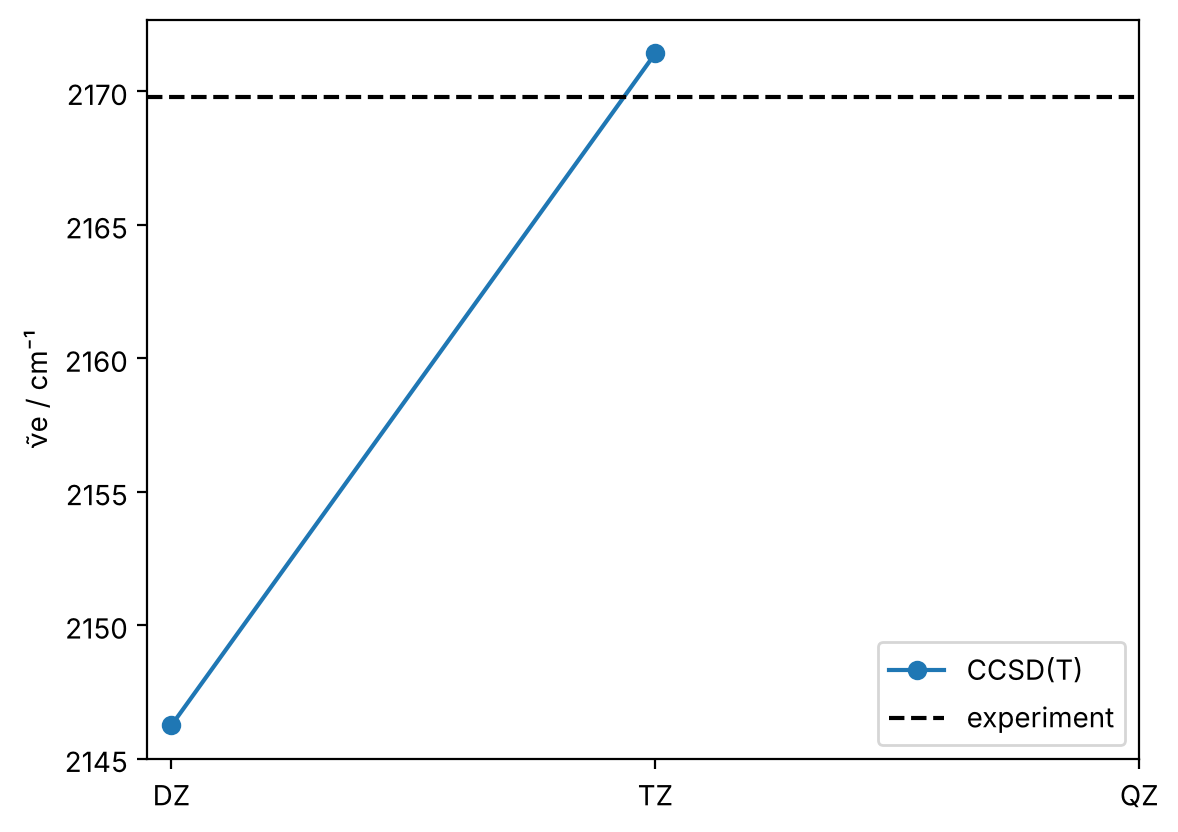

In [4]:
basis_list = ["cc-pvdz", "cc-pvtz"]      # add "cc-pvqz" if time allows
conv = {}
for b in basis_list:
    E = np.array([co_energy(r, "ccsd(t)", b) for r in r_pts])
    conv[b] = fit_minimum(r_pts, E, mu_CO)
    print(b, "r_e = %.4f A  wn = %.0f cm^-1" % (conv[b][0], conv[b][2]))
X = [{"cc-pvdz": 2, "cc-pvtz": 3, "cc-pvqz": 4}[b] for b in conv]
plt.plot(X, [conv[b][2] for b in conv], "o-", label="CCSD(T)")
plt.axhline(2169.8, color="k", ls="--", label="experiment")
plt.xticks([2, 3, 4], ["DZ", "TZ", "QZ"]); plt.ylabel("ν̃e / cm⁻¹"); plt.legend(); plt.show()

## 4. The dipole moment, and why CO absorbs infrared light

Unlike O₂, CO is **heteronuclear**, so its dipole is not zero by symmetry. Experimentally
$\mu$ = 0.11 D with the **negative end on carbon** (C⁻O⁺), which is the opposite of what electronegativity suggests.

PySCF reports the dipole vector $\boldsymbol\mu = \sum_A Z_A \mathbf R_A - \int \rho(\mathbf r)\,\mathbf r\, d\mathbf r$,
which points from − to +. With C at the origin and O on +z, C⁻O⁺ means $\mu_z > 0$.

For a correlated method, use its density matrix:
`dm = mycc.make_rdm1(ao_repr=True)` then `mf.dip_moment(dm=dm, unit="Debye", verbose=0)`.

**Exercise 4.**
(a) Compute $\mu_z$ at r = 1.128 Å with HF, B3LYP (`dft.RKS(mol, xc="b3lyp")`) and CCSD in cc-pVTZ.
Which gets the sign right?
(b) With B3LYP, compute $\mu_z$ at 1.10 and 1.16 Å and estimate $d\mu/dr$ by a central difference.

In [5]:
def co_dipole(r, method="b3lyp", basis="cc-pvtz"):
    """z component of the CO dipole (debye); C at the origin, O on +z."""
    mol = gto.M(atom=[["C", (0, 0, 0)], ["O", (0, 0, r)]], basis=basis, verbose=0)
    if method == "b3lyp":
        mf = dft.RKS(mol, xc="b3lyp").run()
        return mf.dip_moment(unit="Debye", verbose=0)[2]
    mf = scf.RHF(mol).run()
    if method == "hf":
        return mf.dip_moment(unit="Debye", verbose=0)[2]
    mycc = cc.CCSD(mf).run()
    return mf.dip_moment(dm=mycc.make_rdm1(ao_repr=True), unit="Debye", verbose=0)[2]

for m in ("hf", "b3lyp", "ccsd"):
    print(f"{m:6s} mu_z = {co_dipole(1.128, m):+.3f} D")
print("expt   mu_z = +0.11 D  (C-O+)")

dmu_dr = (co_dipole(1.16) - co_dipole(1.10)) / 0.06
print(f"\nB3LYP d(mu)/dr = {dmu_dr:.2f} D/A")

hf     mu_z = -0.245 D


b3lyp  mu_z = +0.119 D


ccsd   mu_z = +0.180 D
expt   mu_z = +0.11 D  (C-O+)



B3LYP d(mu)/dr = -3.49 D/A


**Question 4.** The *value* of μ at $r_e$ is tiny, yet CO absorbs strongly at 2143 cm⁻¹. Why?
Which quantity controls the IR intensity? Compare with O₂ (Notebook 1).

*Your answer:*

<div style="background:#fff4e5;border-left:4px solid #e08a00;padding:8px 12px">

**Instructor notes**

HF gives the wrong sign (−0.24 D, C⁺O⁻); B3LYP (+0.12 D) and CCSD (+0.18 D, unrelaxed density) give the right sign. This is a classic failure of HF and a good illustration that a small property can be a delicate balance of two large effects (charge transfer toward O versus the carbon lone pair pointing away). Intensity depends on |dμ/dr|², not on μ itself: |dμ/dr| ≈ 3.5 D/Å here (μ_z decreases on stretching, toward C⁺O⁻), so the band is strong. O₂ has dμ/dr = 0 by symmetry. Note for interested students: the MP2 dipole from PySCF's `make_rdm1` is the *unrelaxed* density and gives the wrong sign; the proper (relaxed) MP2 dipole is the derivative of the energy with respect to an applied electric field.

</div>

## 5. Save a curve for Notebook 3

Notebook 3 solves for the vibrational levels on the CCSD(T) curve. It needs the curve over a
wider range, so compute it from 0.90 to 1.60 Å (about 30 s).

saved co_ccsdt_curve.npz (84 s)


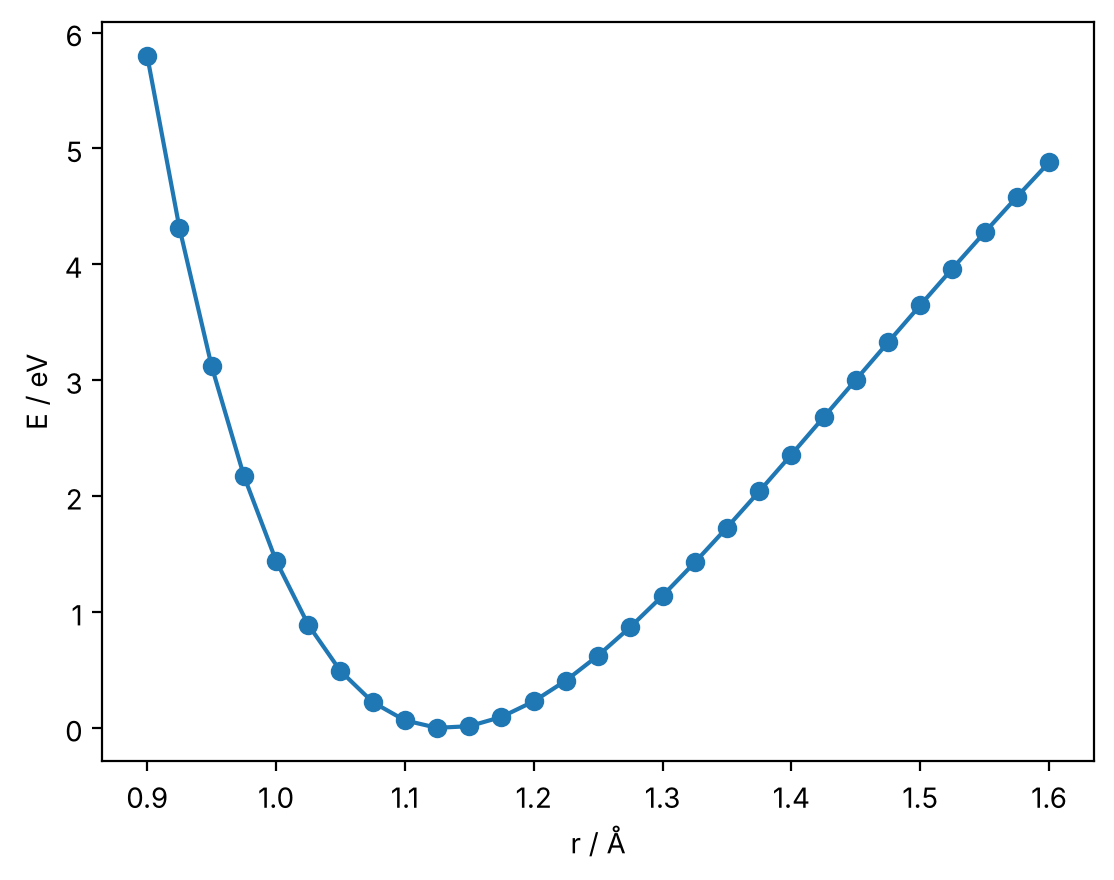

In [6]:
r_wide = np.linspace(0.90, 1.60, 29)
t = time.time()
E_wide = np.array([co_energy(r, "ccsd(t)", "cc-pvtz") for r in r_wide])
mu_wide = np.array([co_dipole(r, "b3lyp") for r in r_wide])
np.savez("co_ccsdt_curve.npz", r=r_wide, E_eV=E_wide - E_wide.min(), mu_D=mu_wide)
print(f"saved co_ccsdt_curve.npz ({time.time() - t:.0f} s)")
plt.plot(r_wide, E_wide - E_wide.min(), "o-"); plt.xlabel("r / Å"); plt.ylabel("E / eV"); plt.show()